# Latihan SKLearn: SVM untuk Klasifikasi Diabetes Pima

Tujuan latihan ini adalah mengklasifikasikan label `Outcome` (0 atau 1) menggunakan Support Vector Machine dari scikit-learn.

Urutan pengerjaan mengikuti screenshot tugas: mengubah data menjadi DataFrame, membagi dataset, melakukan standarisasi, membuat dan melatih model, lalu mengevaluasi model.

## Dataset

Dataset Pima Indians Diabetes berisi delapan atribut dan satu label `Outcome`. Nilai `1` berarti kelas positif diabetes pada dataset, sedangkan `0` berarti kelas negatif. Dataset berisi data historis dan hasil notebook ini hanya untuk pembelajaran; model ini bukan alat diagnosis medis.

Sumber CSV: [Pima-Indians-Diabetes-Dataset di GitHub](https://github.com/npradaschnor/Pima-Indians-Diabetes-Dataset/blob/master/diabetes.csv). Simpan `diabetes.csv` di folder yang sama dengan notebook. Di Google Colab, unggah file tersebut melalui panel Files atau gunakan `from google.colab import files; files.upload()`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## 1. Mengubah data ke dalam DataFrame

Baca file CSV menggunakan pandas dan periksa beberapa baris serta tipe data. Kolom `Outcome` menjadi label yang akan diprediksi.

In [2]:
DATASET_PATH = Path("diabetes.csv")

if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"File {DATASET_PATH} tidak ditemukan. Unduh diabetes.csv dari tautan GitHub "
        "pada bagian Dataset di atas, lalu letakkan di folder notebook."
    )

data = pd.read_csv(DATASET_PATH)
expected_columns = {
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
    "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
}
missing_columns = expected_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"Kolom dataset tidak lengkap: {sorted(missing_columns)}")

print("Ukuran dataset:", data.shape)
data.head()

Ukuran dataset: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
data.info()
print("\nJumlah nilai kosong per kolom:")
display(data.isna().sum())
print("\nDistribusi label Outcome:")
display(data["Outcome"].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Jumlah nilai kosong per kolom:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Distribusi label Outcome:


Outcome
0    500
1    268
Name: count, dtype: int64

## 2. Membagi dataset

Pisahkan atribut (`X`) dari label (`y`), kemudian bagi data menjadi 80% data latih dan 20% data uji. `stratify=y` menjaga proporsi kelas 0 dan 1 tetap serupa pada kedua bagian.

In [4]:
X = data.drop(columns="Outcome")
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 614
Jumlah data uji: 154


## 3. Melakukan standarisasi

SVM sensitif terhadap skala atribut. `StandardScaler` mengubah atribut agar memiliki skala yang sebanding. Scaler di-fit hanya pada data latih, kemudian dipakai untuk mentransformasi data latih dan data uji.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Bentuk data latih setelah standardisasi:", X_train_scaled.shape)
print("Bentuk data uji setelah standardisasi:", X_test_scaled.shape)

Bentuk data latih setelah standardisasi: (614, 8)
Bentuk data uji setelah standardisasi: (154, 8)


## 4. Membuat dan melatih model

Gunakan `SVC` dengan kernel RBF untuk mempelajari batas keputusan klasifikasi dari data latih yang telah distandardisasi.

In [6]:
model = SVC(kernel="rbf")
model.fit(X_train_scaled, y_train)

print("Model SVM selesai dilatih.")

Model SVM selesai dilatih.


## 5. Evaluasi model

Evaluasi prediksi pada data uji yang tidak digunakan untuk melatih model. Laporan menampilkan precision, recall, dan F1-score untuk setiap kelas, selain akurasi dan confusion matrix.

Akurasi data uji: 0.753

Classification report:
                          precision    recall  f1-score   support

      Tidak diabetes (0)       0.80      0.83      0.81       100
Positif pada dataset (1)       0.66      0.61      0.63        54

                accuracy                           0.75       154
               macro avg       0.73      0.72      0.72       154
            weighted avg       0.75      0.75      0.75       154



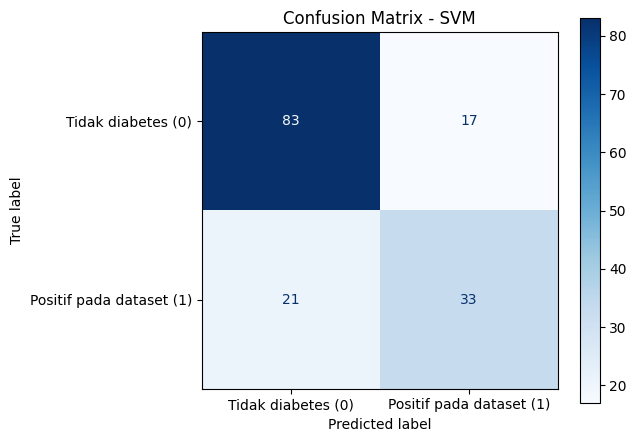

In [7]:
y_pred = model.predict(X_test_scaled)

print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.3f}\n")
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Tidak diabetes (0)", "Positif pada dataset (1)"], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Tidak diabetes (0)", "Positif pada dataset (1)"],
)
display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - SVM")
plt.tight_layout()
plt.show()

## Kesimpulan dan interpretasi

Gunakan confusion matrix untuk membandingkan label aktual dengan prediksi. Precision menunjukkan ketepatan prediksi pada suatu kelas, sedangkan recall menunjukkan berapa banyak contoh aktual kelas tersebut yang berhasil ditemukan. Perhatikan kedua kelas, bukan akurasi saja.

**Pertanyaan untuk laporan:** Berapa akurasi model pada data uji? Dari confusion matrix, berapa prediksi kelas positif yang benar dan yang terlewat? Mengapa hasil ini tidak dapat digunakan untuk mendiagnosis pasien?